# 04. Vias e mapas

Ranking das vias com mais acidentes, a partir da base completa e com os nomes padronizados, e mapas
com as coordenadas **reais** de cada acidente.

**O que mudou:** a versão anterior usava uma planilha à parte com 20 vias (com nomes duplicados e
números que não batiam com a base) e um mapa com coordenadas aproximadas digitadas à mão.

In [1]:
import sys
import warnings
from pathlib import Path

# Encontra a raiz do projeto (a pasta que contém src/sinistros) e importa o pacote
raiz = Path.cwd()
while not (raiz / "src" / "sinistros").exists():
    raiz = raiz.parent
sys.path.insert(0, str(raiz / "src"))
warnings.filterwarnings("ignore")

import pandas as pd
from IPython.display import Image, display

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

from sinistros import config, limpeza, analises as an, graficos as gr
from sinistros import mapas
from sinistros.externos import carregar_bairros

df = limpeza.carregar()

## Ranking

In [2]:
vias = an.ranking_vias(df)
vias["top"][["acidentes", "pct_total", "mortos", "letalidade_pct"]]

,acidentes,pct_total,mortos,letalidade_pct
via,,,,
Av. Washington Soares / CE-040,3539,2.71,58,1.61
BR-116,3315,2.54,140,3.95
Avenida General Osório de Paiva,2669,2.04,72,2.55
Avenida Doutor Silas Munguba,1615,1.24,30,1.80
Avenida Godofredo Maciel,1564,1.20,36,2.17
Avenida Presidente Castelo Branco,1552,1.19,53,3.35
Avenida Presidente Costa e Silva,1535,1.17,42,2.74
Avenida Bernardo Manuel,1282,0.98,12,0.94
Avenida Francisco Sá,1245,0.95,16,1.29


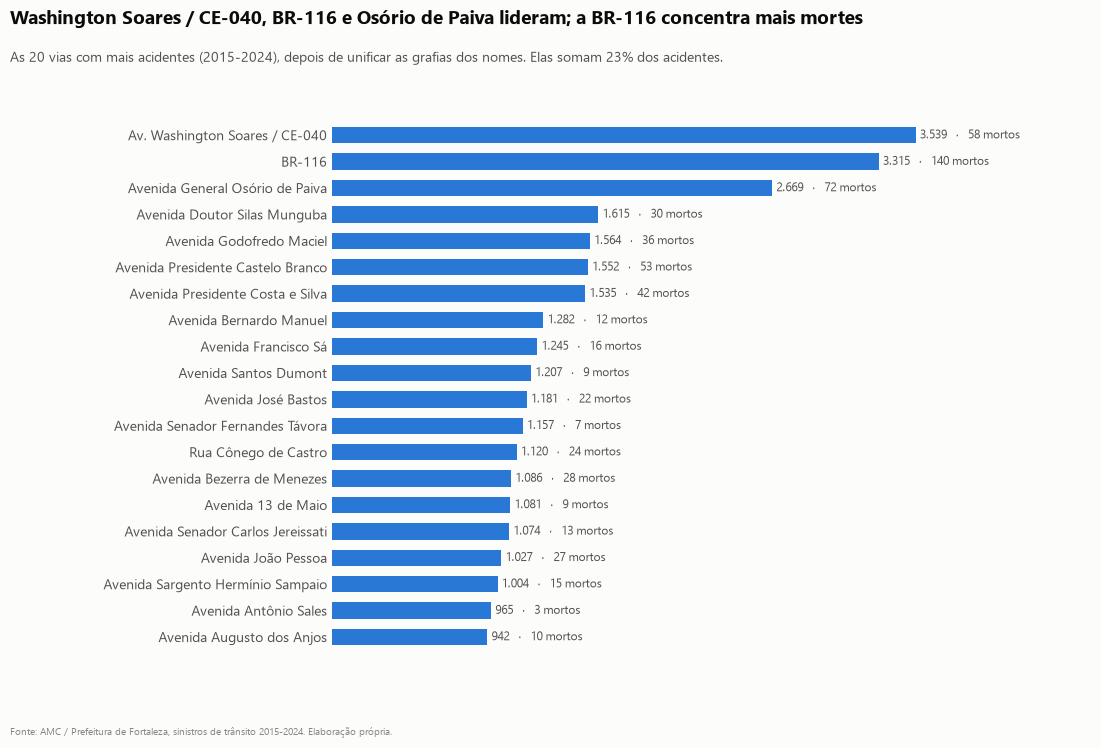

In [3]:
gr.fig23_vias(vias);

- O corredor **Av. Washington Soares / CE-040** lidera (3.539 acidentes), seguido da **BR-116**
  (3.315) e da **Av. General Osório de Paiva** (2.669).
- A **BR-116** é a via com mais mortes (140), mais que o dobro de qualquer outra; sua letalidade
  (4,0%) é quase 3 vezes a média da cidade.
- As 20 vias somam 23% dos acidentes da cidade.

## Mesma via, nomes diferentes

A CE-040 e a Av. Washington Soares são o **mesmo corredor**: dentro de Fortaleza, a rodovia tem nome
de avenida. Os registros usam ora um nome, ora outro, e a troca acontece com o tempo.

In [4]:
mapa_nomes = pd.read_csv(config.ARQ_VIAS_MAPEAMENTO)
corredor = mapa_nomes[mapa_nomes["via"] == "Av. Washington Soares / CE-040"]
grafias_ce040 = corredor[corredor["grafia"].str.contains("ce", case=False)]["grafia"]
nome = df["rua_original"].isin(grafias_ce040).map({True: "registrado como CE-040",
                                                   False: "registrado como Washington Soares"})
pd.crosstab(df.loc[df["via"] == "Av. Washington Soares / CE-040", "ano"],
            nome[df["via"] == "Av. Washington Soares / CE-040"])

rua_original,registrado como CE-040,registrado como Washington Soares
ano,,
2015,489,80
2016,559,104
2017,426,52
2018,209,90
2019,285,81
2020,171,70
2021,121,182
2022,15,172
2023,14,176


Até 2020 predomina "CE-040"; de 2021 em diante, "Washington Soares". Pelas coordenadas, 96% dos
acidentes "CE-040" ficam a menos de 150 m de acidentes "Washington Soares". Contadas separadamente, as
duas apareciam como vias diferentes e nenhuma liderava o ranking. O mesmo acontece com a BR-222 e a
Av. Mister Hull.

## Mapa estático

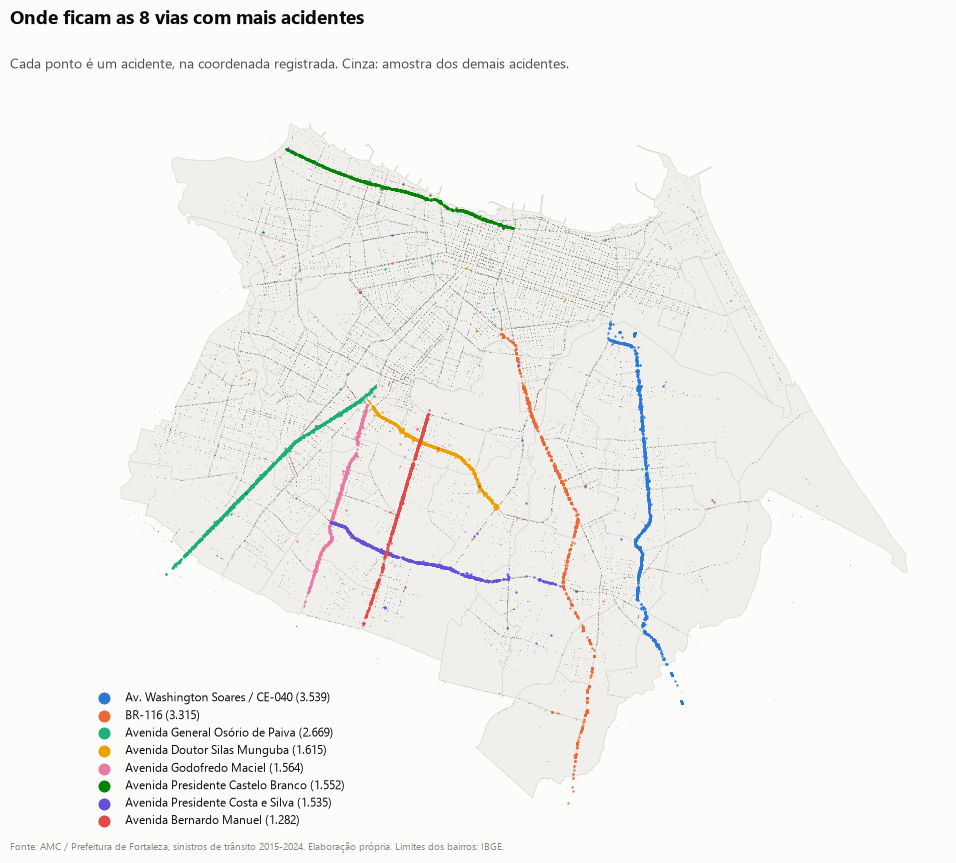

In [5]:
gr.fig24_mapa_vias(df, vias, carregar_bairros());

## Mapa interativo

Arquivo: `figuras/mapas/mapa_interativo.html` (abre no navegador). Camadas que podem ser ligadas e
desligadas: mapa de calor de todos os acidentes; bairros coloridos por acidentes por habitante (passe
o mouse para ver os números); e cada uma das 8 vias com mais acidentes, com os acidentes fatais em
destaque.

In [6]:
bairros = an.tabela_bairros(df)
mapa, caminho = mapas.mapa_interativo(df, bairros, vias["ranking"])
print(caminho)

C:\Users\joaom\Desktop\1. Anady\figuras\mapas\mapa_interativo.html
